# Mangrove canopy monitoring with Sentinel-2 and Random Forest: Tubli Bay, Bahrain

**Theme:** Ecosystem Health, Biodiversity & Blue Carbon  |  **Track:** Very High Resolution (VHR)

This notebook maps the mangrove canopy of one stand in Tubli Bay and tests whether it changed between 2018 and 2025.

1. Builds cloud-masked yearly Sentinel-2 composites (2018-2025) for a small AOI.
2. Maps the canopy two ways: a **rule-based** NDVI/NDWI mask (baseline method) and a **Random Forest** classifier trained on hand-drawn polygons.
3. Scores both on the **same held-out test pixels**, so you can see whether the ML model actually improves on the rules (with one label polygon per class this is a pixel-level split, so the scores are optimistic).
4. Measures NDVI change **inside the canopy only**: multi-year comparison, a persistence test, and a clearance-scale (large drop) test, each compared with a noise floor.
5. Saves figures, tables and a `summary.json` to `results/`.

**Data:** Sentinel-2 Level-2A surface reflectance (`COPERNICUS/S2_SR_HARMONIZED`) via Google Earth Engine. Training labels are polygons drawn by visual interpretation of a public sub-metre satellite basemap (viewing only; no imagery is redistributed in this repository).

**To run:** set the `GEE_PROJECT_ID` environment variable (see README), then run all cells. The labels are loaded from `data/labels/`. Runtime is dominated by Earth Engine calls, so expect several minutes.

## 1. Setup and configuration

In [1]:
import json
import os
import random
from pathlib import Path

import ee
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from matplotlib.patches import Patch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- paths, all relative to the repository root ---
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SAMPLE_DIR = REPO_ROOT / "data" / "sample_input"
LABELS_DIR = REPO_ROOT / "data" / "labels"
RESULTS_DIR = REPO_ROOT / "results"
for _d in (SAMPLE_DIR, LABELS_DIR, RESULTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print("Repository folder:", REPO_ROOT.name)

Repository folder: 813-mangrove-monitoring


In [2]:
# configuration
YEARS = list(range(2018, 2026))
MAX_CLOUDY_PIXEL_PCT = 30            # cloud filter

# rule-based canopy mask (baseline method)
CANOPY_NDVI_MIN = 0.25               # NDVI above this counts as vegetated in a given year
CANOPY_MIN_YEARS = 6                 # analysis years
WATER_NDWI_MAX = 0.0                 # median NDWI
MIN_PATCH_PIXELS = 8                 # drop connected canopy patches smaller than this (10 m pixels)

# Random Forest
TRAIN_FRACTION = 0.7                 # labeled POLYGONS used for training
N_TREES = 200
USE_ML_CANOPY = True                 # True: Random Forest mask drives the change analysis; False: rule-based mask

# change detection (multi-year averages avoid single odd years)
BASELINE_YEARS = [2018, 2019, 2020]
END_YEARS = [2022, 2023, 2025]       # 2024 left out: canopy NDVI is an outlier that year (see section 9)
CONTROL_YEARS = [2021, 2022, 2023]   # compared with the baseline as a rough noise floor
MULTI_DECLINE_THRESHOLD = -0.10
CLEARANCE_THRESHOLD = -0.30          # drops look like canopy turning into bare ground/water/buildings

# interactive labeling is only needed if data/labels/ is empty (see section 5)
DRAW_LABELS = False

In [3]:
# Earth Engine 
# Requires a free Earth Engine account and a Cloud project (see README).
GEE_PROJECT_ID = os.environ.get("GEE_PROJECT_ID")
if not GEE_PROJECT_ID:
    raise EnvironmentError(
        "Set the GEE_PROJECT_ID environment variable to your Earth Engine Cloud project ID, e.g. "
        "run `%env GEE_PROJECT_ID=your-project-id` in a cell above, or export it in your shell."
    )
try:
    ee.Initialize(project=GEE_PROJECT_ID)
except Exception:
    ee.Authenticate()          # opens a browser/login flow the first time
    ee.Initialize(project=GEE_PROJECT_ID)
print("Earth Engine initialized.")


def area_ha(mask_img):
    """Area in hectares of the unmasked pixels of a mask image, within the AOI."""
    val = (
        ee.Image.pixelArea()
        .updateMask(mask_img)
        .reduceRegion(reducer=ee.Reducer.sum(), geometry=aoi, scale=10, maxPixels=1e9)
        .get("area")
    )
    return ee.Number(ee.Algorithms.If(val, val, 0)).divide(10000).getInfo()

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Earth Engine initialized.


## 2. Study area

A ~1.1 km x 1.1 km box drawn around the mangrove stand in Tubli Bay. It is deliberately tight: an earlier box covering the whole bay was mostly open water and urban land, which produced meaningless change numbers. Even this box still contains some water, mudflat, farmland and industrial land, which is why the analysis below works on a **canopy mask** and not on box averages.

In [4]:
mangrove_patch_coords = [
    [50.5879, 26.145461],
    [50.5879, 26.155188],
    [50.59895, 26.155188],
    [50.59895, 26.145461],
    [50.5879, 26.145461],
]
aoi = ee.Geometry.Polygon(mangrove_patch_coords)
aoi_center = aoi.centroid().coordinates().getInfo()      # [lon, lat]
aoi_ha = aoi.area(1).getInfo() / 10000
print(f"AOI centre (lon, lat): {aoi_center}   AOI area: {aoi_ha:.0f} ha")

aoi_geojson = {
    "type": "FeatureCollection",
    "features": [{
        "type": "Feature",
        "properties": {"name": "Mangrove stand, Tubli Bay, Bahrain (hand-drawn AOI)"},
        "geometry": {"type": "Polygon", "coordinates": [mangrove_patch_coords]},
    }],
}
(SAMPLE_DIR / "aoi.geojson").write_text(json.dumps(aoi_geojson, indent=2))

AOI centre (lon, lat): [50.59342499998249, 26.15032453781135]   AOI area: 119 ha


687

## 3. Sentinel-2 yearly composites

One cloud-masked median composite per year over the AOI, with NDVI (vegetation density) and NDMI (vegetation moisture) added.

In [5]:
def mask_s2_clouds(image):
    """Mask clouds and cirrus with the Sentinel-2 QA60 band and scale reflectance to 0-1."""
    qa = image.select("QA60")
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(qa.bitwiseAnd(cirrus_bit_mask).eq(0))
    return image.updateMask(mask).divide(10000).copyProperties(image, ["system:time_start"])


def s2_collection(year):
    return (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(aoi)
        .filterDate(ee.Date.fromYMD(year, 1, 1), ee.Date.fromYMD(year, 12, 31))
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", MAX_CLOUDY_PIXEL_PCT))
    )


def add_indices(image):
    ndvi = image.normalizedDifference(["B8", "B4"]).rename("NDVI")    # NIR, Red
    ndmi = image.normalizedDifference(["B8", "B11"]).rename("NDMI")   # NIR, SWIR1
    return image.addBands([ndvi, ndmi])


yearly_composites = {
    y: add_indices(s2_collection(y).map(mask_s2_clouds).median().clip(aoi)) for y in YEARS
}
yearly_ndvi = {y: yearly_composites[y].select("NDVI") for y in YEARS}
print(f"Built {len(yearly_composites)} yearly composites: {YEARS}")

Built 8 yearly composites: [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [6]:
# Diagnostic: how many scenes went into each composite?
df_scene_counts = pd.DataFrame(
    [{"year": y, "n_scenes": s2_collection(y).size().getInfo()} for y in YEARS]
)
display(df_scene_counts)

# Whole-box NDVI/NDMI means per year, kept only to show how much the surroundings dilute the canopy signal later
records = []
for y in YEARS:
    stats = yearly_composites[y].select(["NDVI", "NDMI"]).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=aoi, scale=10, maxPixels=1e9
    ).getInfo()
    records.append({"year": y, "NDVI_mean": stats.get("NDVI"), "NDMI_mean": stats.get("NDMI")})
df_timeseries = pd.DataFrame(records)
display(df_timeseries)

,year,n_scenes
0,2018,54
1,2019,111
2,2020,117
3,2021,120
4,2022,109
5,2023,108
6,2024,120
7,2025,139


,year,NDVI_mean,NDMI_mean
0,2018,0.180572,0.036994
1,2019,0.196651,0.079902
2,2020,0.190068,0.099080
3,2021,0.167579,0.039972
4,2022,0.157516,0.046666
5,2023,0.160027,0.063575
6,2024,0.163213,0.030422
7,2025,0.170545,0.046260


## 4. Baseline canopy mask: rules on NDVI and NDWI

A pixel counts as canopy if it is vegetated (NDVI above a threshold) in most years, is not water (median NDWI), and belongs to a patch of at least `MIN_PATCH_PIXELS` pixels. This is simple and transparent, but the thresholds are hand-tuned and farmland that stays green all year passes the test. The Random Forest below is meant to fix that.

In [7]:
veg_years = ee.ImageCollection.fromImages(
    [yearly_ndvi[y].gt(CANOPY_NDVI_MIN) for y in YEARS]
).sum()

ndwi_median = ee.ImageCollection.fromImages(
    [yearly_composites[y].normalizedDifference(["B3", "B8"]).rename("NDWI") for y in YEARS]
).median()

rules_raw = veg_years.gte(CANOPY_MIN_YEARS).And(ndwi_median.lt(WATER_NDWI_MAX)).selfMask()
rules_patch = rules_raw.connectedPixelCount(maxSize=100, eightConnected=True)
canopy_mask_rules = rules_raw.updateMask(rules_patch.gte(MIN_PATCH_PIXELS)).clip(aoi)

rules_ha = area_ha(canopy_mask_rules)
print(f"Rule-based canopy mask: {rules_ha:.1f} ha (AOI is {aoi_ha:.0f} ha)")

Rule-based canopy mask: 37.8 ha (AOI is 119 ha)


## 5. Training labels

The Random Forest learns from polygons labeled **canopy** (class 1) and **not canopy** (class 0). The labels are visual interpretation of a public sub-metre satellite basemap: one hand-traced polygon per class, the canopy outline and the rest of the AOI around it. They are stored in `data/labels/` so this notebook runs without any drawing.

The not-canopy polygon covers the surfaces the model must not confuse with mangrove: farmland and gardens, open water, intertidal flats and algae mats, bare sand, housing and industrial lots.

**How labels are loaded (in priority order):**
1. `data/labels/canopy_polygons.geojson` and `other_polygons.geojson`, if they exist.
2. Coordinate lists pasted into `TRAIN_CANOPY_POLYS` / `TRAIN_OTHER_POLYS` below, which are written to those files.
3. Polygons drawn on the two interactive maps, if `DRAW_LABELS = True` (needs `geemap`; set the flag in section 1, run the two map cells, draw, then run the capture cell).

In [8]:
# Optional interactive labeling maps (only when DRAW_LABELS = True). Draw INSIDE the mangrove canopy on map 1.
if DRAW_LABELS:
    import geemap
    Map_lab_canopy = geemap.Map(center=[aoi_center[1], aoi_center[0]], zoom=16, basemap="HYBRID")
    Map_lab_canopy.addLayer(aoi, {"color": "white"}, "AOI")
    display(Map_lab_canopy)
else:
    print("DRAW_LABELS is False: skipping the interactive labeling maps (labels come from data/labels/).")

DRAW_LABELS is False: skipping the interactive labeling maps (labels come from data/labels/).


In [9]:
# Optional interactive labeling map 2: draw on everything that is NOT canopy (farmland, water, flats, lagoon, sand, buildings).
if DRAW_LABELS:
    Map_lab_other = geemap.Map(center=[aoi_center[1], aoi_center[0]], zoom=16, basemap="HYBRID")
    Map_lab_other.addLayer(aoi, {"color": "white"}, "AOI")
    display(Map_lab_other)

In [10]:
CANOPY_LABEL_FILE = LABELS_DIR / "canopy_polygons.geojson"
OTHER_LABEL_FILE = LABELS_DIR / "other_polygons.geojson"

TRAIN_CANOPY_POLYS = [[[50.593865, 26.145634], [50.593157, 26.145615], [50.591848, 26.147136], [50.590861, 26.148388], [50.590389, 26.149717], [50.59026, 26.150064], [50.590131, 26.150738], [50.590625, 26.15095], [50.590239, 26.151528], [50.590303, 26.151933], [50.590131, 26.152356], [50.590303, 26.152607], [50.590239, 26.15305], [50.590968, 26.153339], [50.59114, 26.153705], [50.590882, 26.15382], [50.590947, 26.154436], [50.59159, 26.154822], [50.592062, 26.154841], [50.592577, 26.155091], [50.593286, 26.15513], [50.593479, 26.15486], [50.59365, 26.154225], [50.594809, 26.153011], [50.595217, 26.152453], [50.595217, 26.151586], [50.59571, 26.151085], [50.594637, 26.150257], [50.595002, 26.14939], [50.59335, 26.148812], [50.592899, 26.148388], [50.593951, 26.146019], [50.593865, 26.145634]]]
TRAIN_OTHER_POLYS = [[[50.587943, 26.145528], [50.587964, 26.155197], [50.59247, 26.155216], [50.591934, 26.154851], [50.591419, 26.154793], [50.590818, 26.154581], [50.590281, 26.153714], [50.589681, 26.152308], [50.590067, 26.150363], [50.590324, 26.149342], [50.590754, 26.148321], [50.591462, 26.147608], [50.592449, 26.14651], [50.593221, 26.14549], [50.594487, 26.14626], [50.594251, 26.147108], [50.593972, 26.147666], [50.593457, 26.148726], [50.59526, 26.149477], [50.594766, 26.150247], [50.597534, 26.151518], [50.593361, 26.155245], [50.598961, 26.155168], [50.598897, 26.145557], [50.587943, 26.145528]]]

def rings_to_geojson(rings, cls):
    return {
        "type": "FeatureCollection",
        "features": [
            {"type": "Feature", "properties": {"class": cls},
             "geometry": {"type": "Polygon", "coordinates": [ring]}}
            for ring in rings
        ],
    }


def fc_to_rings(fc):
    """Outer rings of the polygons in an ee.FeatureCollection (used for drawn labels)."""
    rings = []
    for f in fc.getInfo()["features"]:
        geom = f["geometry"]
        if geom["type"] == "Polygon":
            rings.append([[round(p[0], 6), round(p[1], 6)] for p in geom["coordinates"][0]])
    return rings


def load_rings(path):
    gj = json.loads(path.read_text())
    return [f["geometry"]["coordinates"][0] for f in gj["features"]]


def save_labels(canopy_rings, other_rings):
    CANOPY_LABEL_FILE.write_text(json.dumps(rings_to_geojson(canopy_rings, 1)))
    OTHER_LABEL_FILE.write_text(json.dumps(rings_to_geojson(other_rings, 0)))


if TRAIN_CANOPY_POLYS and TRAIN_OTHER_POLYS:
    save_labels(TRAIN_CANOPY_POLYS, TRAIN_OTHER_POLYS)
    print("Wrote label files from the pasted coordinate lists.")

if CANOPY_LABEL_FILE.exists() and OTHER_LABEL_FILE.exists():
    canopy_rings, other_rings = load_rings(CANOPY_LABEL_FILE), load_rings(OTHER_LABEL_FILE)
    label_source = "data/labels/*.geojson"
elif DRAW_LABELS:
    rois_c, rois_o = Map_lab_canopy.user_rois, Map_lab_other.user_rois
    if rois_c is None or rois_o is None:
        raise ValueError("Draw polygons on BOTH labeling maps above before running this cell.")
    canopy_rings = fc_to_rings(ee.FeatureCollection(rois_c))
    other_rings = fc_to_rings(ee.FeatureCollection(rois_o))
    save_labels(canopy_rings, other_rings)
    label_source = "drawn on the interactive maps (now saved to data/labels/ - commit these files)"
else:
    raise FileNotFoundError(
        "No labels found in data/labels/. Either restore canopy_polygons.geojson and other_polygons.geojson, "
        "paste coordinate lists into TRAIN_CANOPY_POLYS / TRAIN_OTHER_POLYS, or set DRAW_LABELS = True in section 1."
    )

canopy_fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Polygon([r]), {"class": 1}) for r in canopy_rings])
other_fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Polygon([r]), {"class": 0}) for r in other_rings])
labels = canopy_fc.merge(other_fc)
print(f"Labels loaded from {label_source}: {len(canopy_rings)} canopy polygons, {len(other_rings)} not-canopy polygons")

Wrote label files from the pasted coordinate lists.
Labels loaded from data/labels/*.geojson: 1 canopy polygons, 1 not-canopy polygons


## 6. Random Forest canopy classifier

**Features (14):** multi-year median of Sentinel-2 bands B2-B8, B11, B12; NDWI and NDMI; and the mean, standard deviation and minimum of NDVI across 2018-2025. Mangrove canopy is persistently green and stable, while tidal flats and seasonal crops fluctuate, so the temporal features are meant to help separate them.

**Testing:** the notebook is built to hold out whole polygons for testing (`TRAIN_FRACTION` of polygons train, the rest test), because neighbouring pixels are highly correlated and mixing pixels from the same polygon into both sets inflates accuracy. With the committed labels (one polygon per class) that split is not possible, so the notebook falls back to a random pixel-level split and says so. The accuracy below comes from that fallback and is optimistic.

In [11]:
S2_BANDS = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B11", "B12"]

spectral = ee.ImageCollection.fromImages(
    [yearly_composites[y].select(S2_BANDS) for y in YEARS]
).median()

ndwi_ml = spectral.normalizedDifference(["B3", "B8"]).rename("NDWI")
ndmi_ml = spectral.normalizedDifference(["B8", "B11"]).rename("NDMI")

ndvi_stats = ee.ImageCollection.fromImages([yearly_ndvi[y] for y in YEARS]).reduce(
    ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True).combine(ee.Reducer.min(), sharedInputs=True)
)  # bands: NDVI_mean, NDVI_stdDev, NDVI_min

feature_image = spectral.addBands([ndwi_ml, ndmi_ml, ndvi_stats]).clip(aoi)
FEATURE_NAMES = feature_image.bandNames().getInfo()
print(f"{len(FEATURE_NAMES)} features:", FEATURE_NAMES)

14 features: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B11', 'B12', 'NDWI', 'NDMI', 'NDVI_mean', 'NDVI_stdDev', 'NDVI_min']


In [12]:
labels = labels.randomColumn("rand", SEED)
train_polys = labels.filter(ee.Filter.lt("rand", TRAIN_FRACTION))
test_polys = labels.filter(ee.Filter.gte("rand", TRAIN_FRACTION))

# the rule-based mask rides along as an extra band so it is scored on exactly the same test pixels
sample_image = feature_image.addBands(canopy_mask_rules.unmask(0).rename("rules"))


def sample(polys):
    return sample_image.sampleRegions(collection=polys, properties=["class"], scale=10, tileScale=4)


def class_counts(fc):
    hist = fc.aggregate_histogram("class").getInfo()
    return {int(float(k)): v for k, v in hist.items()}


train_s, test_s = sample(train_polys), sample(test_polys)
ct, cv = class_counts(train_s), class_counts(test_s)

if len(ct) < 2 or len(cv) < 2:
    print("WARNING: the polygon-level split left a class missing in train or test (too few polygons).")
    print("Falling back to a pixel-level split: accuracy will be OPTIMISTIC.")
    all_s = sample(labels).randomColumn("rand2", SEED)
    train_s = all_s.filter(ee.Filter.lt("rand2", TRAIN_FRACTION))
    test_s = all_s.filter(ee.Filter.gte("rand2", TRAIN_FRACTION))
    ct, cv = class_counts(train_s), class_counts(test_s)
    split_mode = "pixel-level (optimistic)"
else:
    split_mode = "polygon-level (held-out polygons)"

print(f"Split: {split_mode}")
print(f"Train pixels per class (0 = other, 1 = canopy): {ct}")
print(f"Test pixels per class:                          {cv}")


def balance(fc):
    """Subsample the larger class so both classes have equal pixel counts."""
    c = class_counts(fc)
    k = min(c.get(0, 0), c.get(1, 0))
    if k == 0:
        raise ValueError("A class has no training pixels: draw more polygons.")
    parts = [
        fc.filter(ee.Filter.eq("class", cls)).randomColumn("r", SEED).sort("r").limit(k)
        for cls in (0, 1)
    ]
    return parts[0].merge(parts[1])


train_bal = balance(train_s)
clf = ee.Classifier.smileRandomForest(numberOfTrees=N_TREES, seed=SEED).train(
    features=train_bal, classProperty="class", inputProperties=FEATURE_NAMES
)
print("Random Forest trained.")

Falling back to a pixel-level split: accuracy will be OPTIMISTIC.
Split: pixel-level (optimistic)
Train pixels per class (0 = other, 1 = canopy): {0: 5726, 1: 2636}
Test pixels per class:                          {0: 2433, 1: 1137}
Random Forest trained.


,overall_acc,kappa,canopy_precision,canopy_recall,canopy_F1,canopy_IoU,n_test_pixels
Rule-based mask,0.933,0.846,0.893,0.897,0.895,0.810,3570.0
Random Forest,0.986,0.968,0.977,0.980,0.978,0.958,3570.0


Random Forest confusion matrix [[TN, FP], [FN, TP]]: [[2407, 26], [23, 1114]]
Split mode: pixel-level (optimistic). Labels are visual interpretation, not field data; with a pixel-level split, test pixels sit next to training pixels, so this score is optimistic.


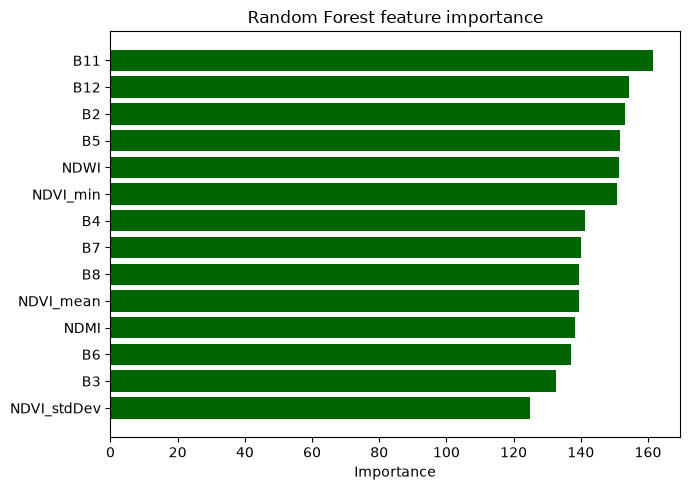

In [13]:
def metrics_from_matrix(m):
    (tn, fp), (fn, tp) = m   # rows = actual (0, 1), columns = predicted (0, 1)
    total = tn + fp + fn + tp
    oa = (tn + tp) / total if total else float("nan")
    prec = tp / (tp + fp) if (tp + fp) else float("nan")
    rec = tp / (tp + fn) if (tp + fn) else float("nan")
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else float("nan")
    iou = tp / (tp + fp + fn) if (tp + fp + fn) else float("nan")
    pe = ((tn + fp) * (tn + fn) + (fn + tp) * (fp + tp)) / (total ** 2) if total else float("nan")
    kappa = (oa - pe) / (1 - pe) if total and (1 - pe) else float("nan")
    return {"overall_acc": oa, "kappa": kappa, "canopy_precision": prec,
            "canopy_recall": rec, "canopy_F1": f1, "canopy_IoU": iou, "n_test_pixels": total}


test_pred = test_s.classify(clf, "rf_pred")
cm_rf = test_pred.errorMatrix("class", "rf_pred", [0, 1]).getInfo()
cm_rules = test_s.errorMatrix("class", "rules", [0, 1]).getInfo()

df_acc = pd.DataFrame(
    {"Rule-based mask": metrics_from_matrix(cm_rules), "Random Forest": metrics_from_matrix(cm_rf)}
).T.round(3)
display(df_acc)
print("Random Forest confusion matrix [[TN, FP], [FN, TP]]:", cm_rf)
print(f"Split mode: {split_mode}. Labels are visual interpretation, not field data; with a pixel-level split, "
      "test pixels sit next to training pixels, so this score is optimistic.")

importance = ee.Dictionary(clf.explain().get("importance")).getInfo()
importance = dict(sorted(importance.items(), key=lambda kv: kv[1]))
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(list(importance.keys()), list(importance.values()), color="darkgreen")
ax.set_xlabel("Importance")
ax.set_title("Random Forest feature importance")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "rf_feature_importance.png", dpi=150)
plt.show()

## 7. Classify the AOI and compare with the rule-based mask

In [14]:
rf_raw = feature_image.classify(clf).eq(1).selfMask()
rf_patch = rf_raw.connectedPixelCount(maxSize=100, eightConnected=True)
rf_mask = rf_raw.updateMask(rf_patch.gte(MIN_PATCH_PIXELS)).clip(aoi)

rf0, rules0 = rf_mask.unmask(0), canopy_mask_rules.unmask(0)
both = rf0.And(rules0).selfMask()
rf_only = rf0.And(rules0.Not()).selfMask()
rules_only = rules0.And(rf0.Not()).selfMask()
union = rf0.Or(rules0).selfMask()

rf_ha = area_ha(rf_mask)
both_ha, rf_only_ha, rules_only_ha, union_ha = area_ha(both), area_ha(rf_only), area_ha(rules_only), area_ha(union)

print(f"Rule-based canopy:    {rules_ha:.1f} ha")
print(f"Random Forest canopy: {rf_ha:.1f} ha")
print(f"  agreed: {both_ha:.1f} ha | Random Forest only: {rf_only_ha:.1f} ha | rules only: {rules_only_ha:.1f} ha")
print(f"  overlap (IoU): {both_ha / union_ha:.2f}")

Rule-based canopy:    37.8 ha
Random Forest canopy: 37.8 ha
  agreed: 33.1 ha | Random Forest only: 4.7 ha | rules only: 4.7 ha
  overlap (IoU): 0.78


In [15]:
# Choose which mask drives the change analysis below
canopy_mask = rf_mask if USE_ML_CANOPY else canopy_mask_rules
canopy_ha = area_ha(canopy_mask)
print(f"Active canopy mask: {'Random Forest' if USE_ML_CANOPY else 'rule-based'} ({canopy_ha:.1f} ha)")

Active canopy mask: Random Forest (37.8 ha)


## 8. Canopy-only time series

NDVI and NDMI averaged **inside the canopy mask** only, shown next to the whole-box means from section 3. The gap between the two lines is how much water, farmland and industrial land dilute a box average.

,year,NDVI_mean,NDMI_mean,canopy_NDVI,canopy_NDMI,n_scenes
0,2018,0.181,0.037,0.506,0.191,54
1,2019,0.197,0.080,0.530,0.231,111
2,2020,0.190,0.099,0.503,0.249,117
3,2021,0.168,0.040,0.511,0.184,120
4,2022,0.158,0.047,0.500,0.204,109
5,2023,0.160,0.064,0.511,0.203,108
6,2024,0.163,0.030,0.580,0.208,120
7,2025,0.171,0.046,0.502,0.186,139


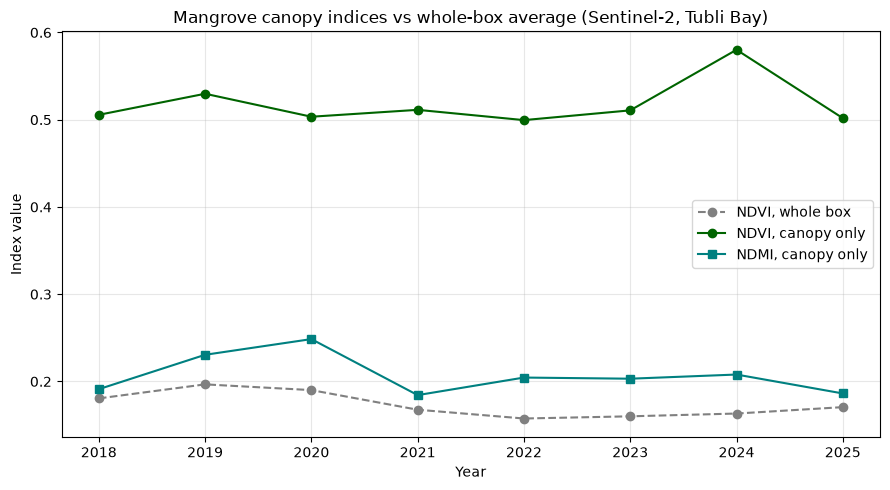

In [16]:
records = []
for y in YEARS:
    stats = (
        yearly_composites[y].select(["NDVI", "NDMI"]).updateMask(canopy_mask)
        .reduceRegion(reducer=ee.Reducer.mean(), geometry=aoi, scale=10, maxPixels=1e9)
        .getInfo()
    )
    records.append({"year": y, "canopy_NDVI": stats.get("NDVI"), "canopy_NDMI": stats.get("NDMI")})

df_canopy = pd.DataFrame(records)
df_compare = df_timeseries.merge(df_canopy, on="year").merge(df_scene_counts, on="year")
display(df_compare.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df_compare["year"], df_compare["NDVI_mean"], marker="o", linestyle="--", color="gray", label="NDVI, whole box")
ax.plot(df_compare["year"], df_compare["canopy_NDVI"], marker="o", color="darkgreen", label="NDVI, canopy only")
ax.plot(df_compare["year"], df_compare["canopy_NDMI"], marker="s", color="teal", label="NDMI, canopy only")
ax.set_xlabel("Year")
ax.set_ylabel("Index value")
ax.set_title("Mangrove canopy indices vs whole-box average (Sentinel-2, Tubli Bay)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "canopy_timeseries.png", dpi=150)
plt.show()

## 9. Change detection inside the canopy

Three tests, each with a reference for what "no real change" looks like:

- **Consecutive-year noise floor.** The same decline test between neighbouring years. Large values flag an odd composite (a year that jumps up and falls back), not real loss. Pairs involving such a year should be ignored, which is why `END_YEARS` skips 2024 by default (check the table: edit `END_YEARS` if your run shows a different outlier).
- **Multi-year comparison.** Baseline-period mean NDVI vs end-period mean NDVI, with a control comparison (`CONTROL_YEARS` vs baseline) as the noise floor. Only an end-vs-baseline number clearly above the control number is evidence of change.
- **Persistent decline.** A pixel counts only if it is below the baseline in **every** end year individually, which removes one-off artifacts such as tide state.

A **clearance-scale** threshold (-0.3) separates large drops (canopy replaced by bare ground, water or buildings) from the small drops typical of stress, tide and moisture effects.

In [17]:
def decline_mask(diff_img, thr):
    """Canopy pixels whose NDVI change is below thr (a negative number)."""
    return diff_img.updateMask(canopy_mask).lt(thr).selfMask()


rows = []
for y0, y1 in zip(YEARS[:-1], YEARS[1:]):
    ha = area_ha(decline_mask(yearly_ndvi[y1].subtract(yearly_ndvi[y0]), MULTI_DECLINE_THRESHOLD))
    rows.append({"pair": f"{y0}->{y1}", "flagged_ha": round(ha, 2), "pct_of_canopy": round(100 * ha / canopy_ha, 1)})
df_noise = pd.DataFrame(rows)
print(f"Consecutive-year decline (NDVI drop > {abs(MULTI_DECLINE_THRESHOLD)}) inside the canopy:")
display(df_noise)

Consecutive-year decline (NDVI drop > 0.1) inside the canopy:


,pair,flagged_ha,pct_of_canopy
0,2018->2019,0.48,1.3
1,2019->2020,0.32,0.9
2,2020->2021,0.16,0.4
3,2021->2022,0.44,1.2
4,2022->2023,0.54,1.4
5,2023->2024,0.29,0.8
6,2024->2025,15.69,41.5


In [18]:
def period_mean_ndvi(years):
    return ee.ImageCollection.fromImages([yearly_ndvi[y] for y in years]).mean()


base_ndvi, end_ndvi, control_ndvi = (period_mean_ndvi(BASELINE_YEARS), period_mean_ndvi(END_YEARS),
                                     period_mean_ndvi(CONTROL_YEARS))
diff_end = end_ndvi.subtract(base_ndvi).rename("NDVI_change")
diff_control = control_ndvi.subtract(base_ndvi).rename("NDVI_change")


def mean_canopy_ndvi(img):
    return img.updateMask(canopy_mask).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=aoi, scale=10, maxPixels=1e9
    ).get("NDVI").getInfo()


ndvi_base_mean = mean_canopy_ndvi(base_ndvi)
ndvi_end_mean = mean_canopy_ndvi(end_ndvi)
ndvi_control_mean = mean_canopy_ndvi(control_ndvi)
print(f"Mean canopy NDVI  baseline {BASELINE_YEARS}: {ndvi_base_mean:.3f}")
print(f"                  control  {CONTROL_YEARS}: {ndvi_control_mean:.3f}  (change {ndvi_control_mean - ndvi_base_mean:+.3f})")
print(f"                  end      {END_YEARS}: {ndvi_end_mean:.3f}  (change {ndvi_end_mean - ndvi_base_mean:+.3f})")


def persistent_decline_mask(thr):
    """Canopy pixels below the baseline by more than |thr| in EVERY end year."""
    flags = ee.ImageCollection.fromImages(
        [yearly_ndvi[y].subtract(base_ndvi).lt(thr) for y in END_YEARS]
    ).sum()
    return flags.eq(len(END_YEARS)).updateMask(canopy_mask).selfMask()


rows = []
for thr in [-0.05, -0.10, -0.15, -0.20, -0.30]:
    rows.append({
        "threshold": thr,
        "end_vs_baseline_ha": round(area_ha(decline_mask(diff_end, thr)), 2),
        "persistent_every_end_year_ha": round(area_ha(persistent_decline_mask(thr)), 2),
        "control_vs_baseline_ha": round(area_ha(decline_mask(diff_control, thr)), 2),
    })
df_multi = pd.DataFrame(rows)
df_multi["end_pct_of_canopy"] = (100 * df_multi["end_vs_baseline_ha"] / canopy_ha).round(1)
display(df_multi)

Mean canopy NDVI  baseline [2018, 2019, 2020]: 0.513
                  control  [2021, 2022, 2023]: 0.507  (change -0.006)
                  end      [2022, 2023, 2025]: 0.504  (change -0.009)


,threshold,end_vs_baseline_ha,persistent_every_end_year_ha,control_vs_baseline_ha,end_pct_of_canopy
0,-0.05,5.73,2.29,4.58,15.2
1,-0.10,1.44,0.81,0.73,3.8
2,-0.15,0.56,0.21,0.13,1.5
3,-0.20,0.17,0.04,0.04,0.4
4,-0.30,0.00,0.00,0.00,0.0


In [19]:
clear_mean = decline_mask(diff_end, CLEARANCE_THRESHOLD)
clear_persist = persistent_decline_mask(CLEARANCE_THRESHOLD)
clear_mean_ha, clear_persist_ha = area_ha(clear_mean), area_ha(clear_persist)

print(f"Clearance-scale loss (NDVI drop > {abs(CLEARANCE_THRESHOLD)}) inside the {canopy_ha:.1f} ha canopy:")
print(f"  multi-year mean:              {clear_mean_ha:.2f} ha ({100 * clear_mean_ha / canopy_ha:.1f}% of canopy)")
print(f"  persistent in every end year: {clear_persist_ha:.2f} ha ({100 * clear_persist_ha / canopy_ha:.1f}% of canopy)")


def zone_table(mask_img, diff_img, top_n=15):
    """Polygons for each flagged patch with centroid, area and mean NDVI change (for visual checks)."""
    vectors = mask_img.reduceToVectors(
        geometry=aoi, scale=10, geometryType="polygon", eightConnected=True, maxPixels=1e9
    )
    vectors = diff_img.reduceRegions(collection=vectors, reducer=ee.Reducer.mean(), scale=10)

    def add_props(f):
        c = f.geometry().centroid(1).coordinates()
        return f.set({"ha": f.geometry().area(1).divide(10000), "lon": c.get(0), "lat": c.get(1)})

    vectors = vectors.map(add_props)
    if vectors.size().getInfo() == 0:
        return pd.DataFrame(columns=["zone", "lat", "lon", "area_ha", "mean_ndvi_change"])
    feats = vectors.limit(500, "ha", False).getInfo()["features"]
    rows = [
        {"lat": round(f["properties"]["lat"], 5), "lon": round(f["properties"]["lon"], 5),
         "area_ha": round(f["properties"]["ha"], 3), "mean_ndvi_change": round(f["properties"]["mean"], 3)}
        for f in feats
    ]
    df = pd.DataFrame(rows).sort_values("area_ha", ascending=False).head(top_n).reset_index(drop=True)
    df.insert(0, "zone", [f"Z{i + 1}" for i in range(len(df))])
    return df


persist_mask = persistent_decline_mask(MULTI_DECLINE_THRESHOLD)
print(f"\nPersistent decline zones (NDVI drop > {abs(MULTI_DECLINE_THRESHOLD)} in every end year), largest first:")
df_zones = zone_table(persist_mask, diff_end)
display(df_zones)

Clearance-scale loss (NDVI drop > 0.3) inside the 37.8 ha canopy:
  multi-year mean:              0.00 ha (0.0% of canopy)
  persistent in every end year: 0.00 ha (0.0% of canopy)

Persistent decline zones (NDVI drop > 0.1 in every end year), largest first:


,zone,lat,lon,area_ha,mean_ndvi_change
0,Z1,26.14889,50.59284,0.582,-0.158
1,Z2,26.14875,50.59110,0.188,-0.191
2,Z3,26.14636,50.59393,0.018,-0.249
3,Z4,26.14686,50.59379,0.009,-0.165
4,Z5,26.14767,50.59343,0.009,-0.108
5,Z6,26.14875,50.59226,0.009,-0.122


## 10. Figures

Static maps with a Sentinel-2 true-colour background, so they render on GitHub and in the slides. They are drawn at Sentinel-2's native 10 m resolution (one block = one pixel, no smoothing). Finer thumbnails exceed Earth Engine's memory limit for this computation. (The sub-metre imagery used for labeling is not redistributed here.)

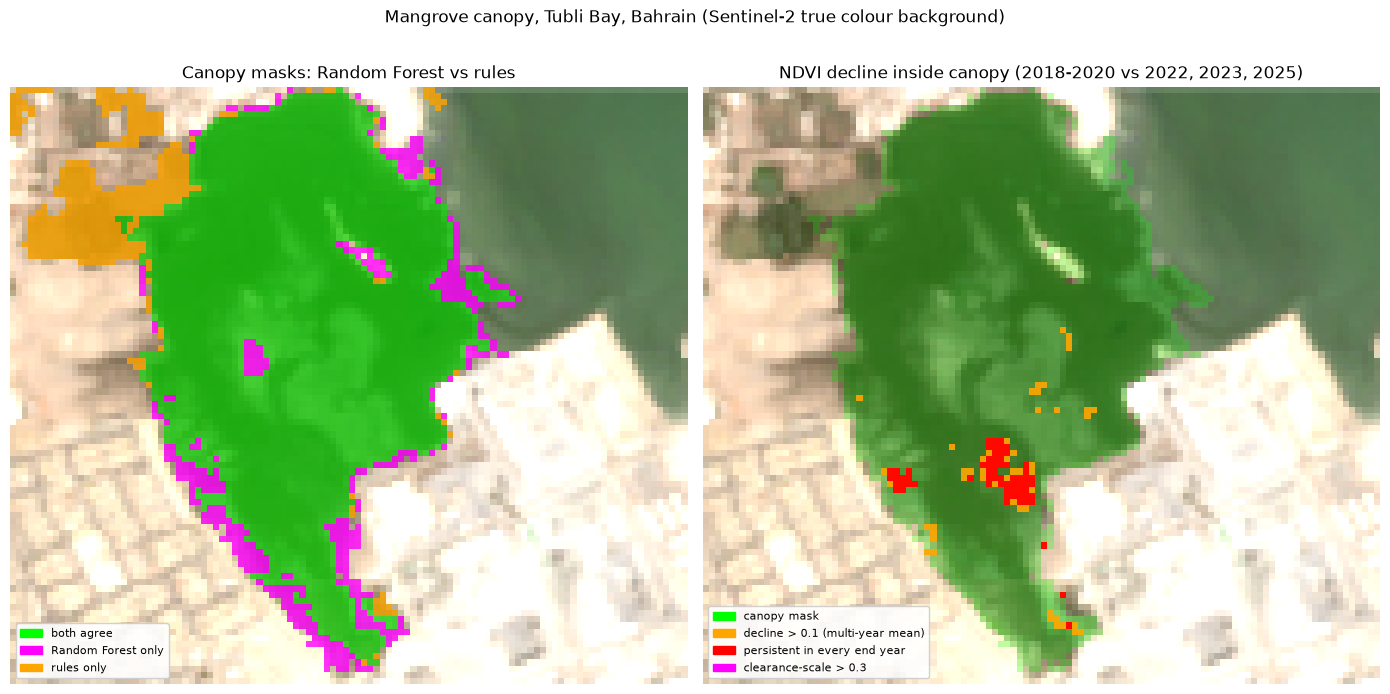

In [20]:
backdrop = spectral.select(["B4", "B3", "B2"]).visualize(min=0.0, max=0.3, gamma=1.4)


def overlay(mask_img, color, opacity=0.6):
    return mask_img.visualize(palette=["000000", color], min=0, max=1, opacity=opacity)


# Earth Engine evaluates a thumbnail at the OUTPUT pixel size, so a fine grid multiplies the work: a 900 px request
# over this ~1.1 km AOI (about 1.2 m pixels) exceeded Earth Engine's memory limit. Ask for the native 10 m grid instead.
_lon_span = max(pt[0] for pt in mangrove_patch_coords) - min(pt[0] for pt in mangrove_patch_coords)
_lat_span = max(pt[1] for pt in mangrove_patch_coords) - min(pt[1] for pt in mangrove_patch_coords)
_width_m = _lon_span * 111320 * np.cos(np.radians(aoi_center[1]))
_height_m = _lat_span * 110574
NATIVE_PX = int(round(max(_width_m, _height_m) / 10))   # pixels across the AOI at Sentinel-2's 10 m resolution
THUMB_OVERSAMPLE = 1   # 2 gives a smoother 5 m picture if Earth Engine allows it; 1 is the safe default


def save_thumb(rgb_image, filename):
    dims = NATIVE_PX * THUMB_OVERSAMPLE
    url = rgb_image.getThumbURL({"region": aoi, "dimensions": dims, "format": "png"})
    resp = requests.get(url, timeout=180)
    if not resp.ok:
        raise RuntimeError(f"Thumbnail request failed ({resp.status_code}) at {dims} px: {resp.text[:300]}")
    path = RESULTS_DIR / filename
    path.write_bytes(resp.content)
    return path


map_masks = (backdrop.blend(overlay(both, "00FF00", 0.55))
             .blend(overlay(rf_only, "FF00FF", 0.8))
             .blend(overlay(rules_only, "FFA500", 0.8)))
map_change = (backdrop.blend(overlay(canopy_mask, "00FF00", 0.25))
              .blend(overlay(decline_mask(diff_end, MULTI_DECLINE_THRESHOLD), "FFA500", 0.9))
              .blend(overlay(persist_mask, "FF0000", 0.95))
              .blend(overlay(clear_mean, "FF00FF", 0.95)))

path_masks = save_thumb(map_masks, "canopy_mask_comparison.png")
path_change = save_thumb(map_change, "change_map.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
panels = [
    (axes[0], path_masks, "Canopy masks: Random Forest vs rules",
     [Patch(color="#00FF00", label="both agree"), Patch(color="#FF00FF", label="Random Forest only"),
      Patch(color="#FFA500", label="rules only")]),
    (axes[1], path_change,
     f"NDVI decline inside canopy ({BASELINE_YEARS[0]}-{BASELINE_YEARS[-1]} vs {', '.join(map(str, END_YEARS))})",
     [Patch(color="#00FF00", label="canopy mask"), Patch(color="#FFA500", label=f"decline > {abs(MULTI_DECLINE_THRESHOLD)} (multi-year mean)"),
      Patch(color="#FF0000", label="persistent in every end year"), Patch(color="#FF00FF", label=f"clearance-scale > {abs(CLEARANCE_THRESHOLD)}")]),
]
for ax, path, title, handles in panels:
    ax.imshow(mpimg.imread(path), interpolation="nearest")   # one block = one 10 m pixel, no smoothing
    ax.set_title(title)
    ax.axis("off")
    ax.legend(handles=handles, loc="lower left", fontsize=8, framealpha=0.9)
fig.suptitle("Mangrove canopy, Tubli Bay, Bahrain (Sentinel-2 true colour background)", fontsize=12)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "example_output.png", dpi=150)
plt.show()

### Smoother version of the main figure

The thumbnails above show every 10 m pixel as a square. The next cell redraws the same figure with a smoothed backdrop and smooth mask outlines, and overwrites `results/example_output.png`. It downloads the ~110 x 108 source pixels once and draws them locally, so Earth Engine never renders a fine grid. The analysis itself is unchanged and still uses the original 10 m pixels. If this cell fails, the thumbnail version above is kept.

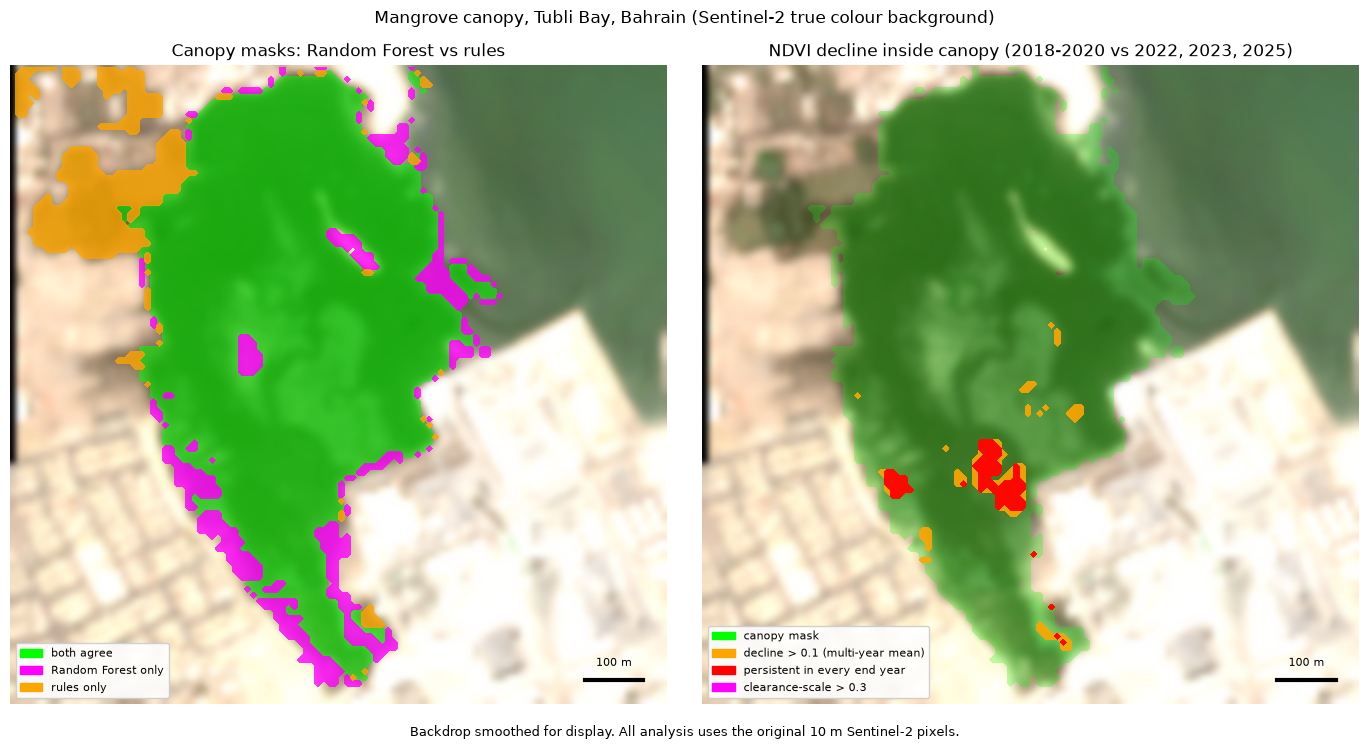

In [21]:
def draw_smooth_figure(grid):
    rgb = np.clip(np.dstack([grid["R"], grid["G"], grid["B"]]) / 0.3, 0, 1) ** (1 / 1.4)   # same stretch as the thumbnails
    H, W = rgb.shape[:2]

    def draw_mask(ax, arr, color, alpha):
        if arr.max() > 0.5:
            ax.contourf(np.arange(W) + 0.5, np.arange(H) + 0.5, arr, levels=[0.5, 1.5], colors=[color], alpha=alpha)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
    for ax in axes:
        ax.imshow(rgb, interpolation="bicubic", extent=(0, W, H, 0))
        ax.set_xlim(0, W)
        ax.set_ylim(H, 0)
        ax.axis("off")
        ax.plot([W - 14, W - 4], [H - 4, H - 4], color="black", lw=3)        # 10 pixels = 100 m
        ax.text(W - 9, H - 6, "100 m", ha="center", va="bottom", fontsize=8)

    draw_mask(axes[0], grid["both"], "#00FF00", 0.55)
    draw_mask(axes[0], grid["rf_only"], "#FF00FF", 0.8)
    draw_mask(axes[0], grid["rules_only"], "#FFA500", 0.8)
    draw_mask(axes[1], grid["canopy"], "#00FF00", 0.25)
    draw_mask(axes[1], grid["decline"], "#FFA500", 0.9)
    draw_mask(axes[1], grid["persist"], "#FF0000", 0.95)
    draw_mask(axes[1], grid["clear"], "#FF00FF", 0.95)

    axes[0].set_title("Canopy masks: Random Forest vs rules")
    axes[0].legend(handles=[Patch(color="#00FF00", label="both agree"), Patch(color="#FF00FF", label="Random Forest only"),
                            Patch(color="#FFA500", label="rules only")], loc="lower left", fontsize=8, framealpha=0.9)
    axes[1].set_title(f"NDVI decline inside canopy ({BASELINE_YEARS[0]}-{BASELINE_YEARS[-1]} vs {', '.join(map(str, END_YEARS))})")
    axes[1].legend(handles=[Patch(color="#00FF00", label="canopy mask"),
                            Patch(color="#FFA500", label=f"decline > {abs(MULTI_DECLINE_THRESHOLD)} (multi-year mean)"),
                            Patch(color="#FF0000", label="persistent in every end year"),
                            Patch(color="#FF00FF", label=f"clearance-scale > {abs(CLEARANCE_THRESHOLD)}")],
                   loc="lower left", fontsize=8, framealpha=0.9)
    fig.suptitle("Mangrove canopy, Tubli Bay, Bahrain (Sentinel-2 true colour background)", fontsize=12)
    fig.text(0.5, 0.012, "Backdrop smoothed for display. All analysis uses the original 10 m Sentinel-2 pixels.",
             ha="center", fontsize=9)
    plt.tight_layout(rect=(0, 0.035, 1, 0.97))
    plt.savefig(RESULTS_DIR / "example_output.png", dpi=200)
    plt.show()


try:
    layers = (
        spectral.select(["B4", "B3", "B2"]).rename(["R", "G", "B"])
        .addBands([
            both.unmask(0).rename("both"),
            rf_only.unmask(0).rename("rf_only"),
            rules_only.unmask(0).rename("rules_only"),
            canopy_mask.unmask(0).rename("canopy"),
            decline_mask(diff_end, MULTI_DECLINE_THRESHOLD).unmask(0).rename("decline"),
            persist_mask.unmask(0).rename("persist"),
            clear_mean.unmask(0).rename("clear"),
        ])
        .toFloat()
    )
    props = (
        layers.reproject(crs="EPSG:32639", scale=10)
        .sampleRectangle(region=aoi, defaultValue=0)
        .getInfo()["properties"]
    )
    draw_smooth_figure({k: np.array(v, dtype=float) for k, v in props.items()})
except Exception as exc:
    print("Could not build the smoother figure; keeping the thumbnail version saved above.")
    print("Reason:", str(exc)[:300])

## 11. Save results and the sample input

Tables and a machine-readable `summary.json` go to `results/`; a small GeoTIFF clip of the AOI (the multi-year median Sentinel-2 bands) goes to `data/sample_input/` as example input.

In [22]:
df_scene_counts.to_csv(RESULTS_DIR / "scene_counts.csv", index=False)
df_compare.round(4).to_csv(RESULTS_DIR / "canopy_vs_box_timeseries.csv", index=False)
df_acc.to_csv(RESULTS_DIR / "accuracy_rules_vs_random_forest.csv")
df_noise.to_csv(RESULTS_DIR / "consecutive_year_noise_floor.csv", index=False)
df_multi.to_csv(RESULTS_DIR / "multi_year_change_table.csv", index=False)
df_zones.to_csv(RESULTS_DIR / "persistent_decline_zones.csv", index=False)

summary = {
    "years": YEARS,
    "baseline_years": BASELINE_YEARS,
    "end_years": END_YEARS,
    "control_years": CONTROL_YEARS,
    "aoi_ha": round(aoi_ha, 1),
    "canopy_ha_active": round(canopy_ha, 2),
    "canopy_ha_random_forest": round(rf_ha, 2),
    "canopy_ha_rules": round(rules_ha, 2),
    "rf_vs_rules_iou": round(both_ha / union_ha, 3),
    "split_mode": split_mode,
    "accuracy": df_acc.to_dict(orient="index"),
    "mean_canopy_ndvi": {"baseline": ndvi_base_mean, "control": ndvi_control_mean, "end": ndvi_end_mean},
    "clearance": {"threshold": CLEARANCE_THRESHOLD, "multi_year_mean_ha": clear_mean_ha,
                  "persistent_ha": clear_persist_ha},
    "multi_year_table": df_multi.to_dict(orient="records"),
    "consecutive_year_pairs": df_noise.to_dict(orient="records"),
}
with open(RESULTS_DIR / "summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved tables, figures and summary.json to results/")

Saved tables, figures and summary.json to results/


In [23]:
# Example input: multi-year median Sentinel-2 bands clipped to the AOI (small GeoTIFF, EPSG:32639, 10 m)
try:
    sample_img = spectral.select(["B2", "B3", "B4", "B8", "B11"]).toFloat()
    url = sample_img.getDownloadURL({"region": aoi, "scale": 10, "crs": "EPSG:32639", "format": "GEO_TIFF"})
    resp = requests.get(url, timeout=180)
    resp.raise_for_status()
    (SAMPLE_DIR / "example_scene.tif").write_bytes(resp.content)
    print(f"Wrote data/sample_input/example_scene.tif ({len(resp.content) / 1024:.0f} KB)")
except Exception as exc:
    print("Could not export the sample GeoTIFF:", exc)

Wrote data/sample_input/example_scene.tif (190 KB)


In [24]:
print("HEADLINE NUMBERS")
print(f"- Canopy mapped ({'Random Forest' if USE_ML_CANOPY else 'rule-based'}): {canopy_ha:.1f} ha inside a {aoi_ha:.0f} ha AOI")
print(f"- Held-out canopy F1: rules {df_acc.loc['Rule-based mask', 'canopy_F1']:.3f} -> Random Forest {df_acc.loc['Random Forest', 'canopy_F1']:.3f} ({split_mode})")
print(f"- Mean canopy NDVI {BASELINE_YEARS} -> {END_YEARS}: {ndvi_base_mean:.3f} -> {ndvi_end_mean:.3f} ({ndvi_end_mean - ndvi_base_mean:+.3f})")
row = df_multi[df_multi["threshold"] == MULTI_DECLINE_THRESHOLD].iloc[0]
print(f"- Decline > {abs(MULTI_DECLINE_THRESHOLD)}: {row['end_vs_baseline_ha']} ha end-vs-baseline, "
      f"{row['persistent_every_end_year_ha']} ha persistent, {row['control_vs_baseline_ha']} ha in the control comparison")
print(f"- Clearance-scale (> {abs(CLEARANCE_THRESHOLD)}) persistent loss: {clear_persist_ha:.2f} ha")

HEADLINE NUMBERS
- Canopy mapped (Random Forest): 37.8 ha inside a 119 ha AOI
- Held-out canopy F1: rules 0.895 -> Random Forest 0.978 (pixel-level (optimistic))
- Mean canopy NDVI [2018, 2019, 2020] -> [2022, 2023, 2025]: 0.513 -> 0.504 (-0.009)
- Decline > 0.1: 1.44 ha end-vs-baseline, 0.81 ha persistent, 0.73 ha in the control comparison
- Clearance-scale (> 0.3) persistent loss: 0.00 ha


## 12. How to read the results, and limitations

- **No ground truth.** Labels are visual interpretation of satellite imagery, not field data. Accuracy figures measure agreement with those labels only.
- **Optimistic test set.** There is one label polygon per class, so test pixels come from the same polygons as training pixels and neighbouring pixels are highly correlated. Treat the Random Forest vs rules gap as indicative, not a measured field accuracy. Several smaller polygons per class, with whole polygons held out, would give a fairer score.
- **10 m pixels.** Sentinel-2 cannot resolve individual trees or small clearings. Anything flagged should be confirmed on sub-metre imagery before being called real.
- **Tide and season.** Intertidal pixels change with tide state and algae cover. The persistence test and noise-floor comparisons reduce this but do not remove it.
- **Single-year outliers.** Check the consecutive-year table and the canopy time series: a year that jumps and falls back is a composite artifact, not an ecological event.
- **Earth Engine drift.** Sentinel-2 archives are reprocessed and extended over time, so re-running later can shift numbers slightly. Seeds and date ranges are fixed.
- **One site, one run.** This is a proof of concept on one stand, not a validated national monitoring product.